In [183]:
from sklearn.linear_model import LogisticRegression
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,OrdinalEncoder
from category_encoders import TargetEncoder
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler)

from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score

In [184]:
import pandas as pd

columns = [
    "age", "sex", "cp", "trestbps",
    "chol", "fbs", "restecg", "thalach",
    "exang", "oldpeak", "slope", "ca",
    "thal", "target"
]

df = pd.read_csv(
    "/home/havin-benoy/Desktop/Pyspiders/ml/Datasets/heart+disease/processed.cleveland.data",
    header=None,
    names=columns,
    na_values="?"
)

df.head(20)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


In [185]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [186]:
df["target"].unique()

array([0, 2, 1, 3, 4])

Note:
- In this dataset target column have mulitiple values
- 0 means Absence of heart disease
- all others means Presence of Heart disease
- so we should convert all the others into the label 1

In [187]:
df.loc[df['target'] > 0, 'target'] = 1

In [188]:
df["target"].unique()

array([0, 1])

### Handling NULL values

In [189]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [190]:

mean_ca = sum(df['ca'].dropna())/299
print(f'mean of df["ca"]: {mean_ca}')


mean_thal = sum(df['thal'].dropna())/299
print(f'mean of df["thal"]: {mean_thal}')


mean of df["ca"]: 0.6722408026755853
mean of df["thal"]: 4.765886287625418


In [191]:
df['ca'] = df["ca"].fillna(mean_ca)
df['thal'] = df['thal'].fillna(mean_thal)

In [192]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    float64
 12  thal      303 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [193]:
x = df.drop(columns='target')
y = df["target"]

In [194]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)

In [195]:
numerical_columns = x.select_dtypes(include = 'number')        # include = ('int','float')
numerical_columns

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.000000,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.000000,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.000000,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.000000,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.000000,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.000000,7.0
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.000000,7.0
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.000000,7.0
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.000000,3.0


### Analysing the outliers in each of the columns using boxplot

In [196]:
for i in numerical_columns.columns:
    print(f'plt.boxplot(df["{i}"])')

plt.boxplot(df["age"])
plt.boxplot(df["sex"])
plt.boxplot(df["cp"])
plt.boxplot(df["trestbps"])
plt.boxplot(df["chol"])
plt.boxplot(df["fbs"])
plt.boxplot(df["restecg"])
plt.boxplot(df["thalach"])
plt.boxplot(df["exang"])
plt.boxplot(df["oldpeak"])
plt.boxplot(df["slope"])
plt.boxplot(df["ca"])
plt.boxplot(df["thal"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7081315dda00>,
 'caps': [<matplotlib.lines.Line2D at 0x7081315ddcd0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7081315dd790>],
 'medians': [<matplotlib.lines.Line2D at 0x7081315de1e0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7081315de480>],
 'means': []}

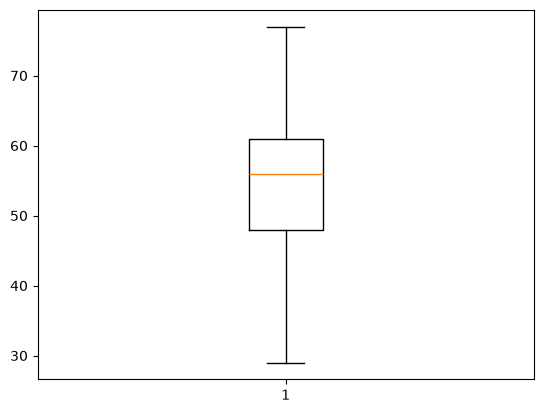

In [197]:
plt.boxplot(df["age"])


{'whiskers': [<matplotlib.lines.Line2D at 0x708131576a80>,
 'caps': [<matplotlib.lines.Line2D at 0x708131827c80>,
 'boxes': [<matplotlib.lines.Line2D at 0x7081316d9c10>],
 'medians': [<matplotlib.lines.Line2D at 0x708131848170>],
 'fliers': [<matplotlib.lines.Line2D at 0x7081318483e0>],
 'means': []}

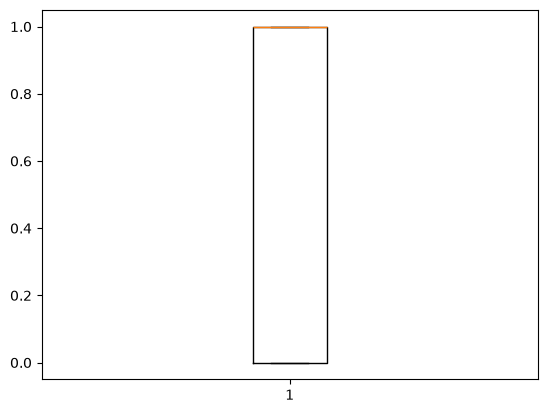

In [198]:
plt.boxplot(df["sex"])


{'whiskers': [<matplotlib.lines.Line2D at 0x70813186b770>,
 'caps': [<matplotlib.lines.Line2D at 0x70813186bc80>,
 'boxes': [<matplotlib.lines.Line2D at 0x70813186b4a0>],
 'medians': [<matplotlib.lines.Line2D at 0x7081318940b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x708131894350>],
 'means': []}

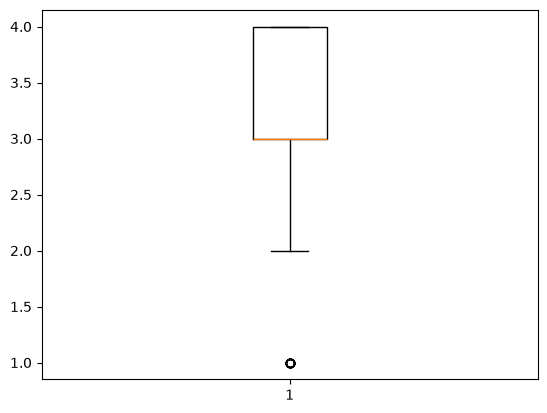

In [199]:
plt.boxplot(df["cp"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7081318d2b10>,
 'caps': [<matplotlib.lines.Line2D at 0x7081318d3020>,
 'boxes': [<matplotlib.lines.Line2D at 0x7081318d2840>],
 'medians': [<matplotlib.lines.Line2D at 0x7081318d3560>],
 'fliers': [<matplotlib.lines.Line2D at 0x7081318d3800>],
 'means': []}

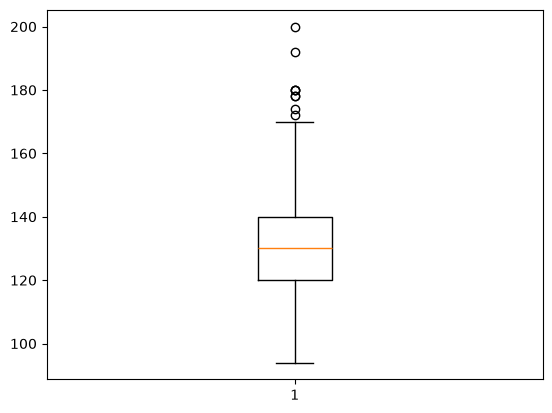

In [200]:
plt.boxplot(df["trestbps"])


{'whiskers': [<matplotlib.lines.Line2D at 0x708131040650>,
 'caps': [<matplotlib.lines.Line2D at 0x708131040b90>,
 'boxes': [<matplotlib.lines.Line2D at 0x708131040410>],
 'medians': [<matplotlib.lines.Line2D at 0x7081310410d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x708131041340>],
 'means': []}

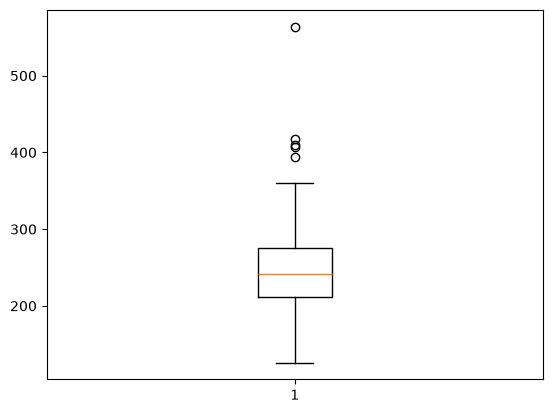

In [201]:
plt.boxplot(df["chol"])


{'whiskers': [<matplotlib.lines.Line2D at 0x70813107da30>,
 'caps': [<matplotlib.lines.Line2D at 0x70813107df70>,
 'boxes': [<matplotlib.lines.Line2D at 0x70813107d790>],
 'medians': [<matplotlib.lines.Line2D at 0x70813107e4b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x70813107e750>],
 'means': []}

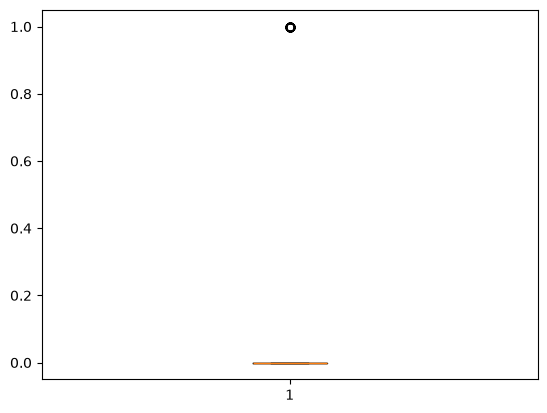

In [202]:
plt.boxplot(df["fbs"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7081310bff50>,
 'caps': [<matplotlib.lines.Line2D at 0x7081310e83b0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7081310bfd40>],
 'medians': [<matplotlib.lines.Line2D at 0x7081310e88f0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7081310e8b90>],
 'means': []}

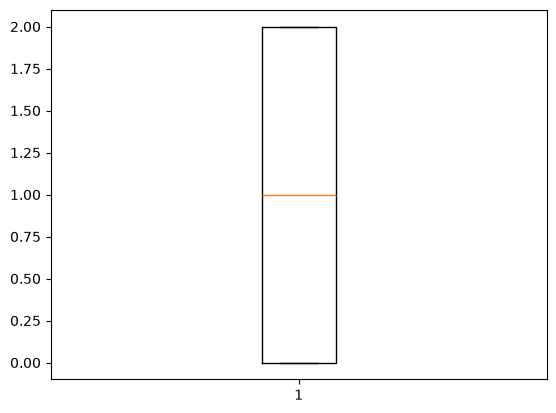

In [203]:
plt.boxplot(df["restecg"])


{'whiskers': [<matplotlib.lines.Line2D at 0x708131717620>,
 'caps': [<matplotlib.lines.Line2D at 0x7081317179e0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7081317173e0>],
 'medians': [<matplotlib.lines.Line2D at 0x708131717f20>],
 'fliers': [<matplotlib.lines.Line2D at 0x708131748200>],
 'means': []}

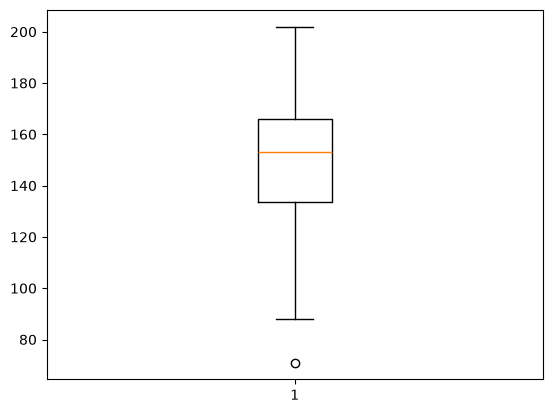

In [204]:
plt.boxplot(df["thalach"])


{'whiskers': [<matplotlib.lines.Line2D at 0x70813178dbe0>,
 'caps': [<matplotlib.lines.Line2D at 0x70813178e0c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x70813178d9a0>],
 'medians': [<matplotlib.lines.Line2D at 0x70813178e5d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x70813178e840>],
 'means': []}

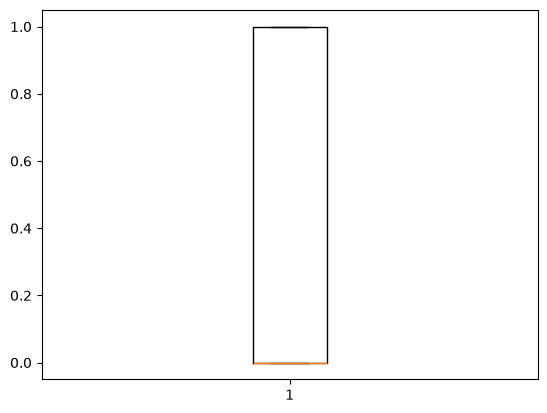

In [205]:
plt.boxplot(df["exang"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7081317cf830>,
 'caps': [<matplotlib.lines.Line2D at 0x7081317cfd10>,
 'boxes': [<matplotlib.lines.Line2D at 0x7081317cf620>],
 'medians': [<matplotlib.lines.Line2D at 0x7081317ce660>],
 'fliers': [<matplotlib.lines.Line2D at 0x7081317cffb0>],
 'means': []}

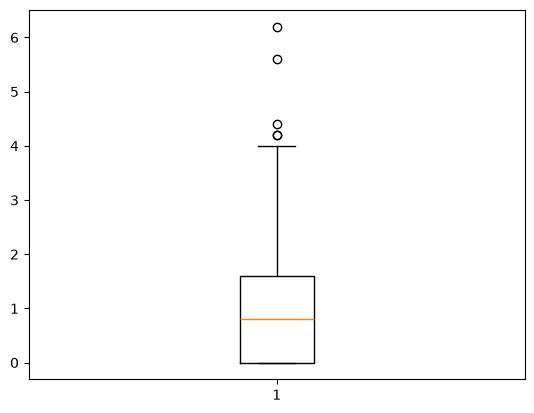

In [206]:
plt.boxplot(df["oldpeak"])


{'whiskers': [<matplotlib.lines.Line2D at 0x708131335010>,
 'caps': [<matplotlib.lines.Line2D at 0x708131335490>,
 'boxes': [<matplotlib.lines.Line2D at 0x708131334d40>],
 'medians': [<matplotlib.lines.Line2D at 0x7081313359a0>],
 'fliers': [<matplotlib.lines.Line2D at 0x708131335c40>],
 'means': []}

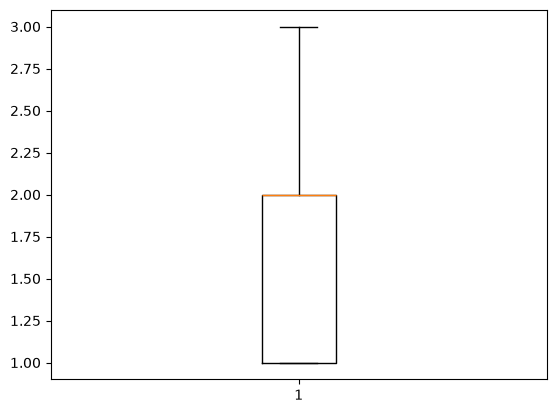

In [207]:
plt.boxplot(df["slope"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7081313a0d10>,
 'caps': [<matplotlib.lines.Line2D at 0x7081313a11c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7081313a0b30>],
 'medians': [<matplotlib.lines.Line2D at 0x7081313a1700>],
 'fliers': [<matplotlib.lines.Line2D at 0x7081313a19a0>],
 'means': []}

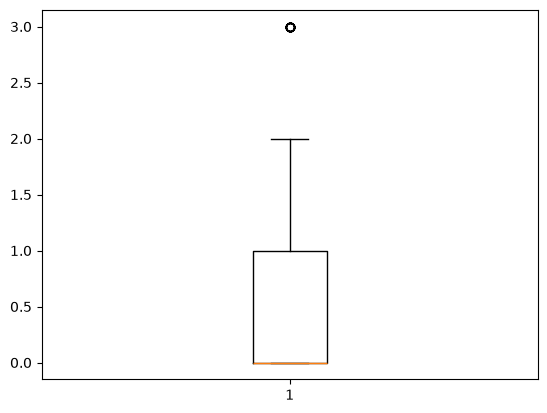

In [208]:
plt.boxplot(df["ca"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7081313e2720>,
 'caps': [<matplotlib.lines.Line2D at 0x7081313e2b10>,
 'boxes': [<matplotlib.lines.Line2D at 0x7081313e24e0>],
 'medians': [<matplotlib.lines.Line2D at 0x7081313e2ff0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7081313e3290>],
 'means': []}

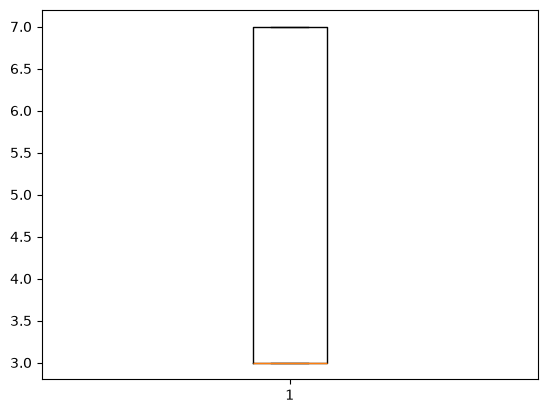

In [209]:
plt.boxplot(df["thal"])

### Based on this , deciding which columns needs which scaling techniques.

In [210]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

In [211]:
columns_for_standard_scaler = ['cp', 'trestbps','chol', 'fbs','thalach','oldpeak','ca']

column_for_min_max_scaler = ['age', 'sex','restecg','exang','slope','thal']

In [212]:
standard_scalar = StandardScaler()
robust_scalar = RobustScaler()
min_max_scaler = MinMaxScaler()

In [213]:
x_train[columns_for_standard_scaler] = standard_scalar.fit_transform(x_train[columns_for_standard_scaler])
x_train[column_for_min_max_scaler] = min_max_scaler.fit_transform(x_train[column_for_min_max_scaler])
x_train.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
132,0.000000,1.0,-1.104690,-0.125982,-0.864142,-0.397360,1.0,2.314470,0.0,-0.873573,0.0,-0.727523,0.0
202,0.583333,1.0,-0.092057,0.974653,-2.483637,2.516611,0.0,1.021242,0.0,-0.704854,0.0,0.393763,1.0
196,0.833333,1.0,-2.117322,1.524970,-0.241260,2.516611,1.0,-0.851710,0.0,-0.789214,0.5,0.393763,0.0
75,0.750000,0.0,-0.092057,1.524970,2.374848,-0.397360,1.0,0.040172,0.0,-0.198698,0.0,-0.727523,0.0
176,0.479167,1.0,0.920575,-1.336680,-0.262023,2.516611,0.0,-0.138205,0.0,-0.789214,0.0,2.636335,1.0


In [214]:
x_test[columns_for_standard_scaler] = standard_scalar.transform(x_test[columns_for_standard_scaler])
x_test[column_for_min_max_scaler] = min_max_scaler.transform(x_test[column_for_min_max_scaler])
x_test.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
179,0.500000,1.0,-0.092057,-0.125982,0.007893,2.516611,1.0,1.021242,0.0,-0.873573,0.0,2.636335,0.0
228,0.520833,1.0,0.920575,-1.226617,-0.822617,-0.397360,1.0,-1.877375,1.0,-0.873573,0.5,0.393763,0.0
111,0.562500,1.0,0.920575,-0.401140,0.070182,2.516611,1.0,-0.271987,1.0,0.138740,0.5,0.393763,0.0
246,0.604167,1.0,0.920575,-1.776934,-0.241260,-0.397360,0.0,0.263142,0.0,-0.789214,0.0,0.393763,1.0
60,0.458333,0.0,0.920575,-0.125982,1.232896,-0.397360,0.0,-0.361175,1.0,0.138740,0.5,-0.727523,1.0


## No need of Encoding since no columns are having string based categorical data.

### Modeling

In [215]:
model = LogisticRegression()
model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [216]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

### Model Performance evaluation by the classification metrics

In [217]:
y.value_counts()

target
0    164
1    139
Name: count, dtype: int64

In [218]:
print(f'percentage of "Absence of Heart disease (0)" samples : {(164/(164+139))*100}\npercentage of "Heart Disease (1)" samples:  {(139/(164+139))*100}')

percentage of "Absence of Heart disease (0)" samples : 54.12541254125413
percentage of "Heart Disease (1)" samples:  45.87458745874587


Conclusion:
- Dataset is balenced
- we can use accuracy as a performance metric

In [219]:
# 1. confusion matrix:
# on train data

cf_train = confusion_matrix(y_train,y_train_pred)

cf_train

array([[122,  13],
       [ 25,  82]])

In [220]:
# 2. recall score (i.e row-wise)

# for label =0 i.e 'Absence of Heart disease'


recall_score_for_0 = cf_train[0,0] / (cf_train[0,0] + cf_train[0,1])

recall_score_for_0

np.float64(0.9037037037037037)

conclusion:
- out of 135, label = 0-'Absence of Heart disease', samples, 
- 90.3% samples are correctly predicted as '0'-'Absence of Heart disease',
- and remaining 9.7% samples are wrongly predicted as '1'-'Heart Disease present'

In [221]:
# recall score for label =1 i.e 'Heart Disease present'
# i.e row-wise

recall_score_for_1 = cf_train[1,1] / (cf_train[1,1] + cf_train[1,0])

recall_score_for_1

np.float64(0.7663551401869159)

conclusion:
- out of 107 , label = 1-'Heart Disease present', samples, 
- 76.6% samples are correctly predicted as '1'-'Heart Disease present',
- and remaining 23.4% samples are wrongly predicted as '0'-'Absence of Heart disease'

In [222]:
# 3. precision score (i.e column-wise)

# for label =0 i.e 'Absence of Heart disease'


precision_score_for_0 = cf_train[0,0] / (cf_train[0,0] + cf_train[1,0])

precision_score_for_0

np.float64(0.8299319727891157)

conclusion:
- out of 147 samples predicted as '0'-'Absence of Heart disease', 
- 82.9% samples are actually '0'-'Absence of Heart disease' samples
- and remaining 17.9% samples are wrongly predicted as '0'-'Absence of Heart disease'

In [223]:
# precision score for label =1 i.e 'Heart Disease present'
# i.e column-wise


precision_score_for_1 = cf_train[1,1] / (cf_train[1,1] + cf_train[0,1])

precision_score_for_1

np.float64(0.8631578947368421)

conclusion:
- out of 95 samples predicted as '1'-'Heart Disease present', 
- 86.3% samples are actually '1'-'Heart Disease present' samples
- and remaining 13.7% samples are wrongly predicted as '1'-'Heart Disease present'

In [224]:
#4. Accuracy


accuracy = (cf_train[1,1]+cf_train[0,0]) / (cf_train[0,0]+cf_train[0,1]+cf_train[1,0] + cf_train[1,1])

print(f'accuracy score is {accuracy}')


accuracy score is 0.8429752066115702


### conclusion:
- out of total 242 predictions, 
- 84.2% of predictions are correct 
- and the remaining  15.8% of predictions are wrong

In [225]:
cf_test = confusion_matrix(y_test,y_test_pred)

cf_test

array([[26,  3],
       [ 3, 29]])

### Directly calling recall, precision and accuracy values 

In [226]:
print(f'Recall score for 0 -(Absence of Heart disease) : {recall_score(y_train,y_train_pred,pos_label = 0)}')
print(f'Recall score for 1 -(Heart Disease present): {recall_score(y_train,y_train_pred,pos_label = 1)}')

Recall score for 0 -(Absence of Heart disease) : 0.9037037037037037
Recall score for 1 -(Heart Disease present): 0.7663551401869159


In [227]:
print(f'Precision score for 0 -(Absence of Heart disease): {precision_score(y_train,y_train_pred,pos_label = 0)}')
print(f'Precision score for 1 -(Heart Disease present): {precision_score(y_train,y_train_pred,pos_label = 1)}')


Precision score for 0 -(Absence of Heart disease): 0.8299319727891157
Precision score for 1 -(Heart Disease present): 0.8631578947368421


In [228]:
print(f'Accuracy score : {accuracy_score(y_train,y_train_pred)}')

Accuracy score : 0.8429752066115702
